# T1 What did we simulate? The prior: reference solution

Questions T1.1, T1.2 of [TASKS.md](../../TASKS.md). The code is in the scripts named below (run from the repository root); this notebook runs them, shows their figures and gives the answers. Every number quoted comes from `results/`.

In [1]:
import os
from pathlib import Path

import IPython.display as ipd

here = Path.cwd()
os.chdir(next(p for p in (here, *here.parents) if (p / "pyproject.toml").exists()))  # the repository root
FIGURES = Path("solutions/stage1_flash/figures")


def show(*names):
    """Display the figures of a question (GIF animates, else the PNG)."""
    for name in names:
        path = next(p for p in (FIGURES / f"{name}.gif", FIGURES / f"{name}.png") if p.exists())
        ipd.display(ipd.Image(filename=str(path), width=900))


## Run the scripts

Data sets are generated on first use and cached in `solutions/stage1_flash/data/`.

In [2]:
!python solutions/stage1_flash/task1_prior.py

T1.1: 200000 events; mean r = 0.6670 m (2/3), median r = 0.7063 m (0.7071)
      fraction r > 0.9 m: 0.1896 (0.19); r < 0.5 m: 0.2496 (0.25)
      KS x0_disc_marginal             D = 0.00157, p = 0.705
      KS y0_disc_marginal             D = 0.00274, p = 0.100
      KS r2_uniform                   D = 0.00131, p = 0.882
      KS r_uniform_wrong_hypothesis   D = 0.25072, p = 0.000
      KS phi_uniform                  D = 0.00237, p = 0.212
      KS energy_uniform               D = 0.00157, p = 0.704
      KS t0_uniform                   D = 0.00263, p = 0.126
T1.2: Q = 600 p.e.: E = 1.931 [1.669, 2.195] MeV (disc prior), 2.192 [2.080, 2.306] MeV (r <= 0.5 m)
      Q = 160 p.e.: 41.8 % of the wide-prior posterior below 0.5 MeV
results -> ./solutions/stage1_flash/results/T1.json


## T1.1 What did we simulate?

E and t0 are flat in [0.5, 5] MeV and [0, 10] ns, and the vertex is uniform in the *area* of the disc. That is why r
is not flat: the ring between r and r + dr has area 2πr dr, so p(r) = 2r/R² and r² is uniform (the generator samples
r = R √u). The marginals of x0 and y0 are semicircles, p(x0) = 2 √(R² − x0²) / (π R²).

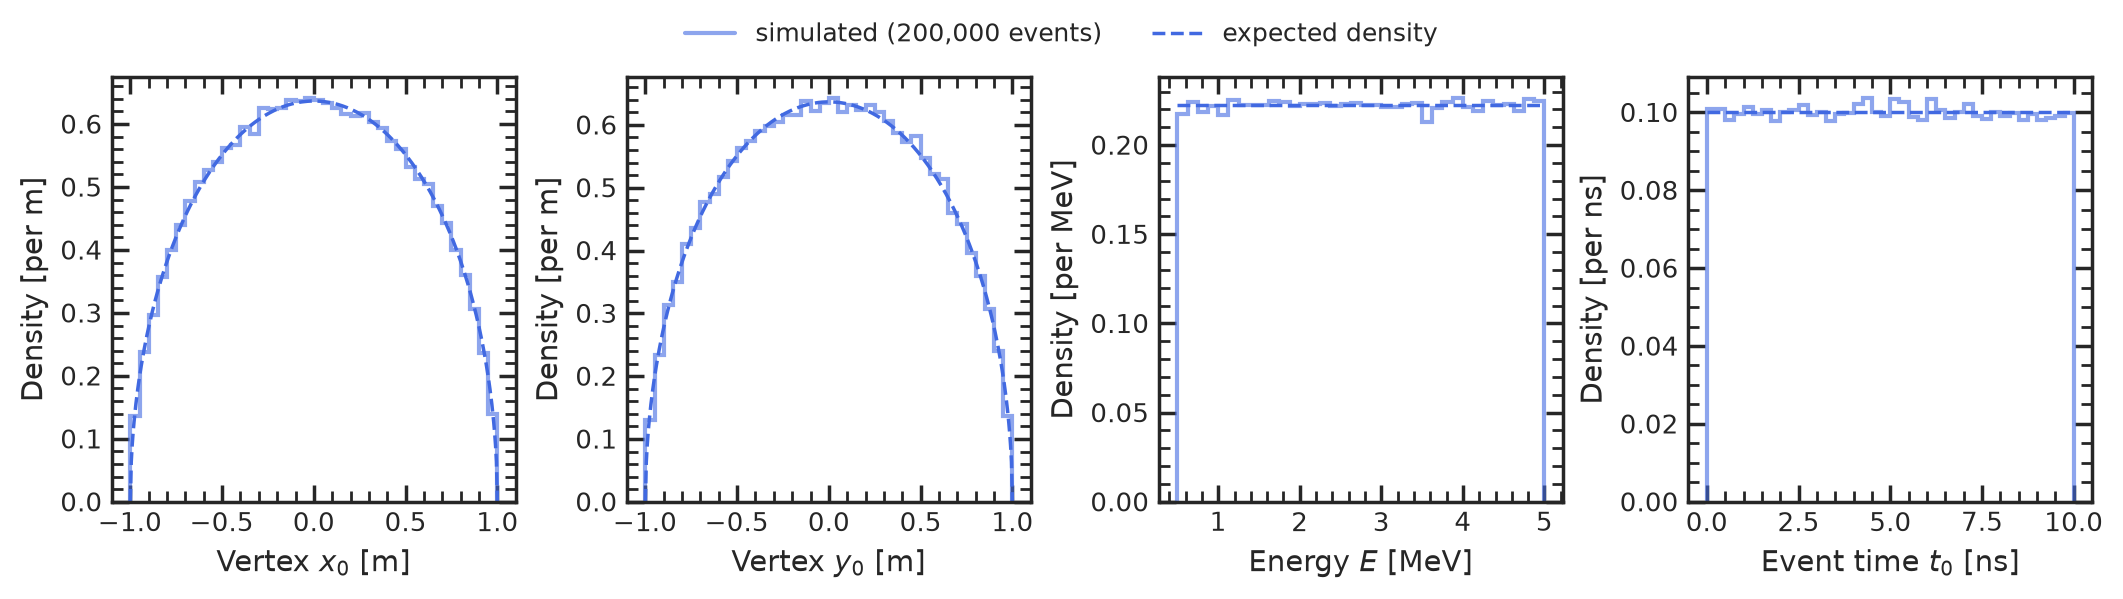

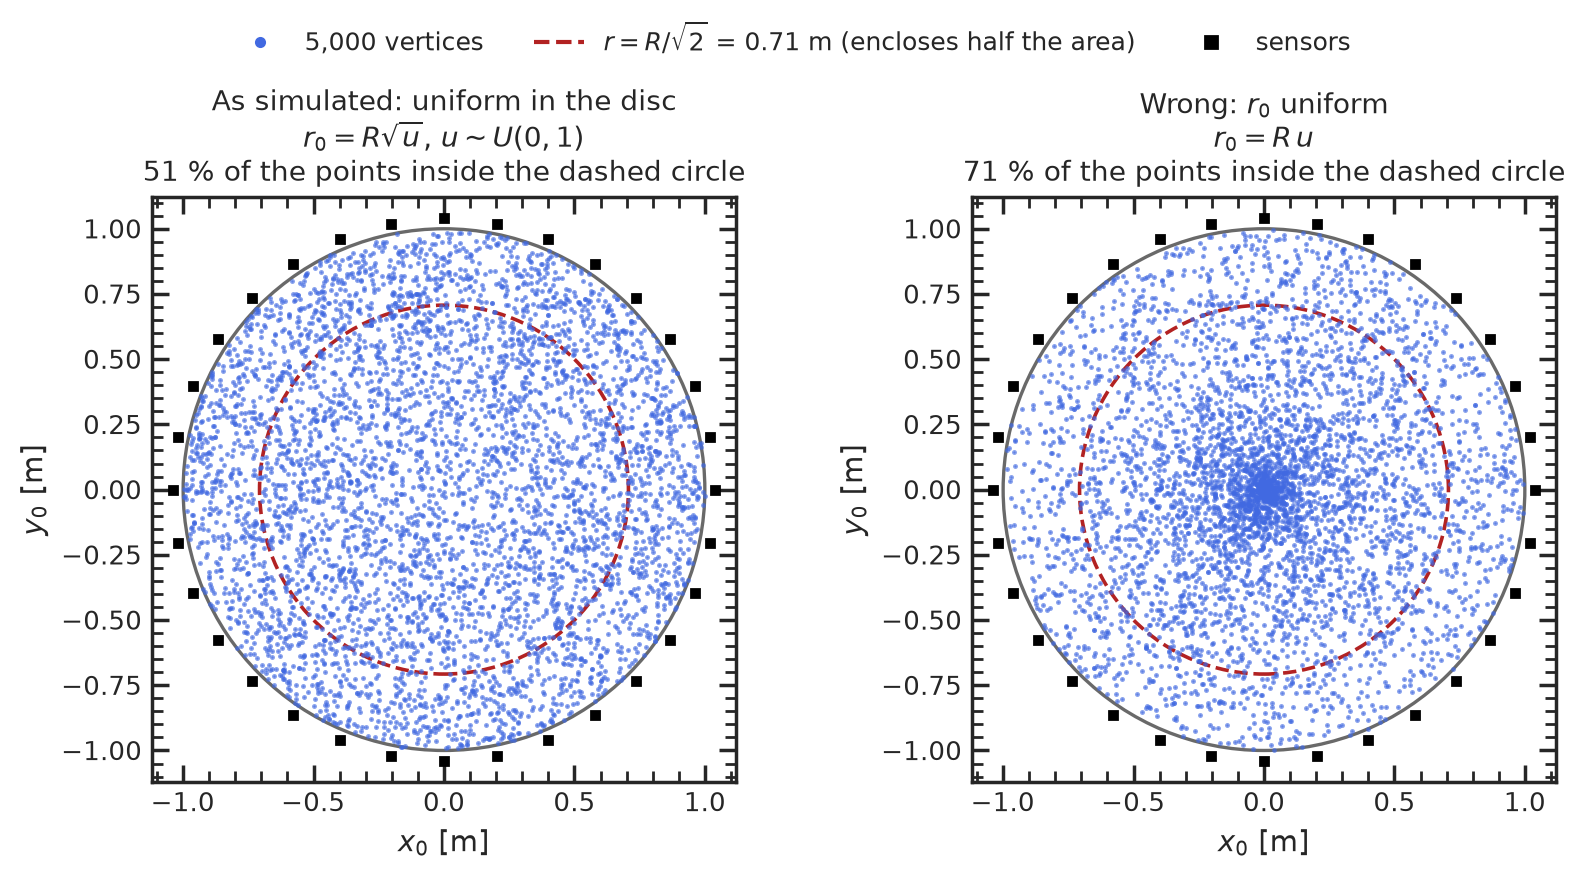

In [3]:
show("t1_1_prior_marginals", "t1_1_vertices")

**Details**

- The histograms follow these densities: KS p-values 0.10-0.88 for x0, y0, E, t0, the azimuth and r².
- Mean r = 0.667 m (expected 2/3), median r = 0.706 m (expected 1/√2 = 0.707); only 25.0 % of the events lie inside
  r < 0.5 m and 19.0 % lie within 10 cm of the wall (r > 0.9 m).

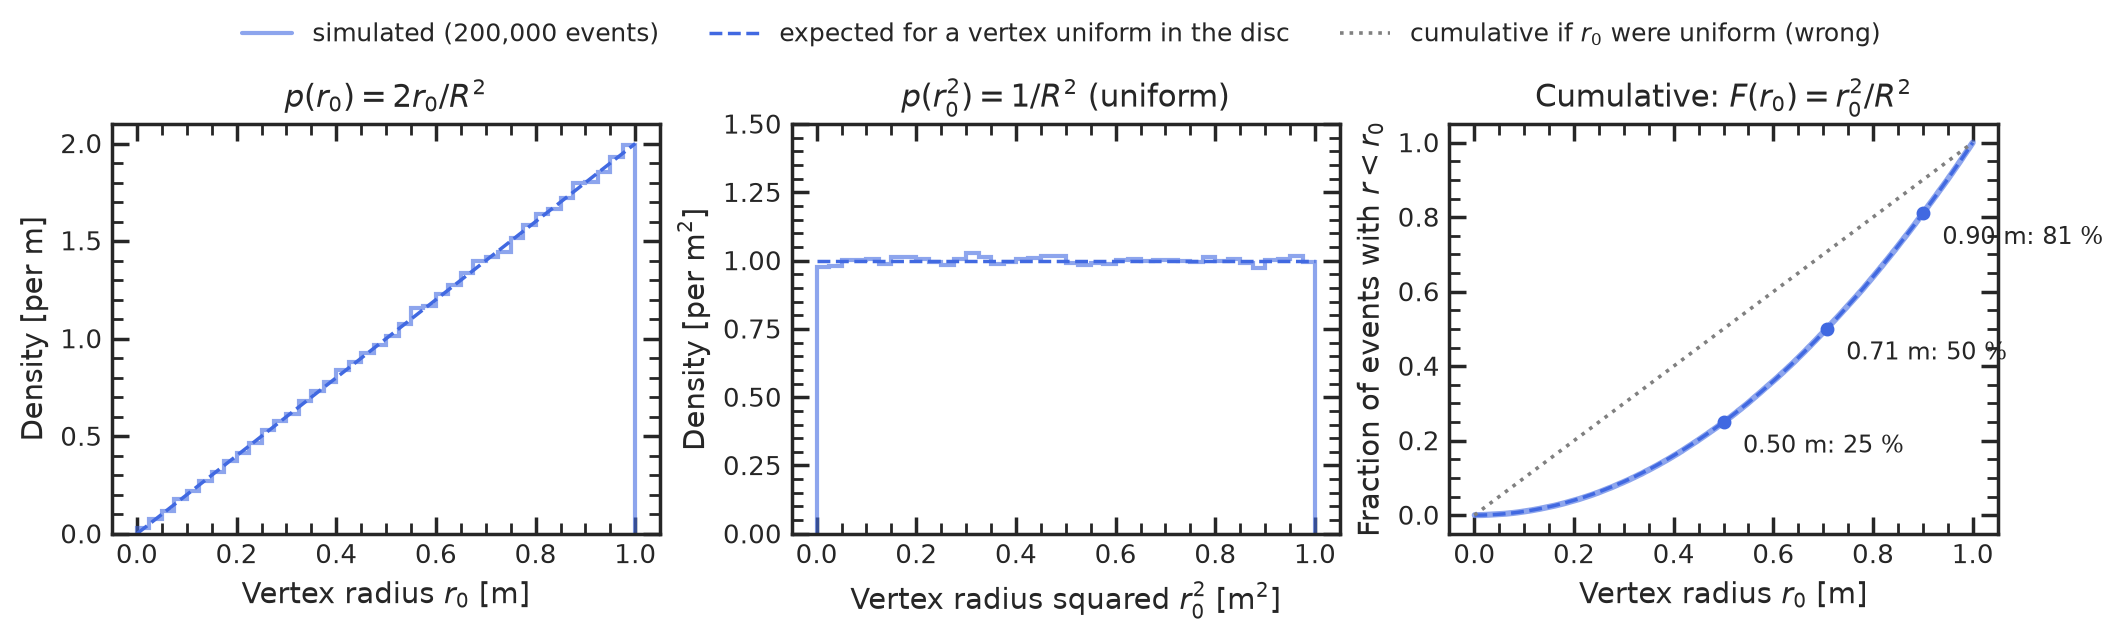

In [4]:
show("t1_1_radius")

- The classic mistake r = R u (right panel of `t1_1_vertices`) piles the vertices up at the centre: it would put 50 %
  of the events inside r < 0.5 m, and the KS test rejects "r uniform" for our sample with D = 0.25.

*Figures:* `t1_1_prior_marginals`, `t1_1_vertices`, `t1_1_radius` (200 000 events of the default prior,
`task1_prior.py`). *Numbers:* `results/T1.json`.

## T1.2 The prior that NPE will use

The prior is π(x0, y0, E) = 1/(π R²) × 1/(4.5 MeV) = 0.0707 per m² per MeV inside the disc r ≤ 1 m and
0.5 ≤ E ≤ 5 MeV, zero outside; t0 ~ U(0, 10) ns is a nuisance parameter that the relative times remove (T2.3). NPE
learns p(θ | x) ∝ p(x | θ) π(θ) from pairs (θ, x) drawn from this prior, so the prior fixes where the posterior can put
probability, how much weight each region gets, and the population over which the coverage of the posterior holds.

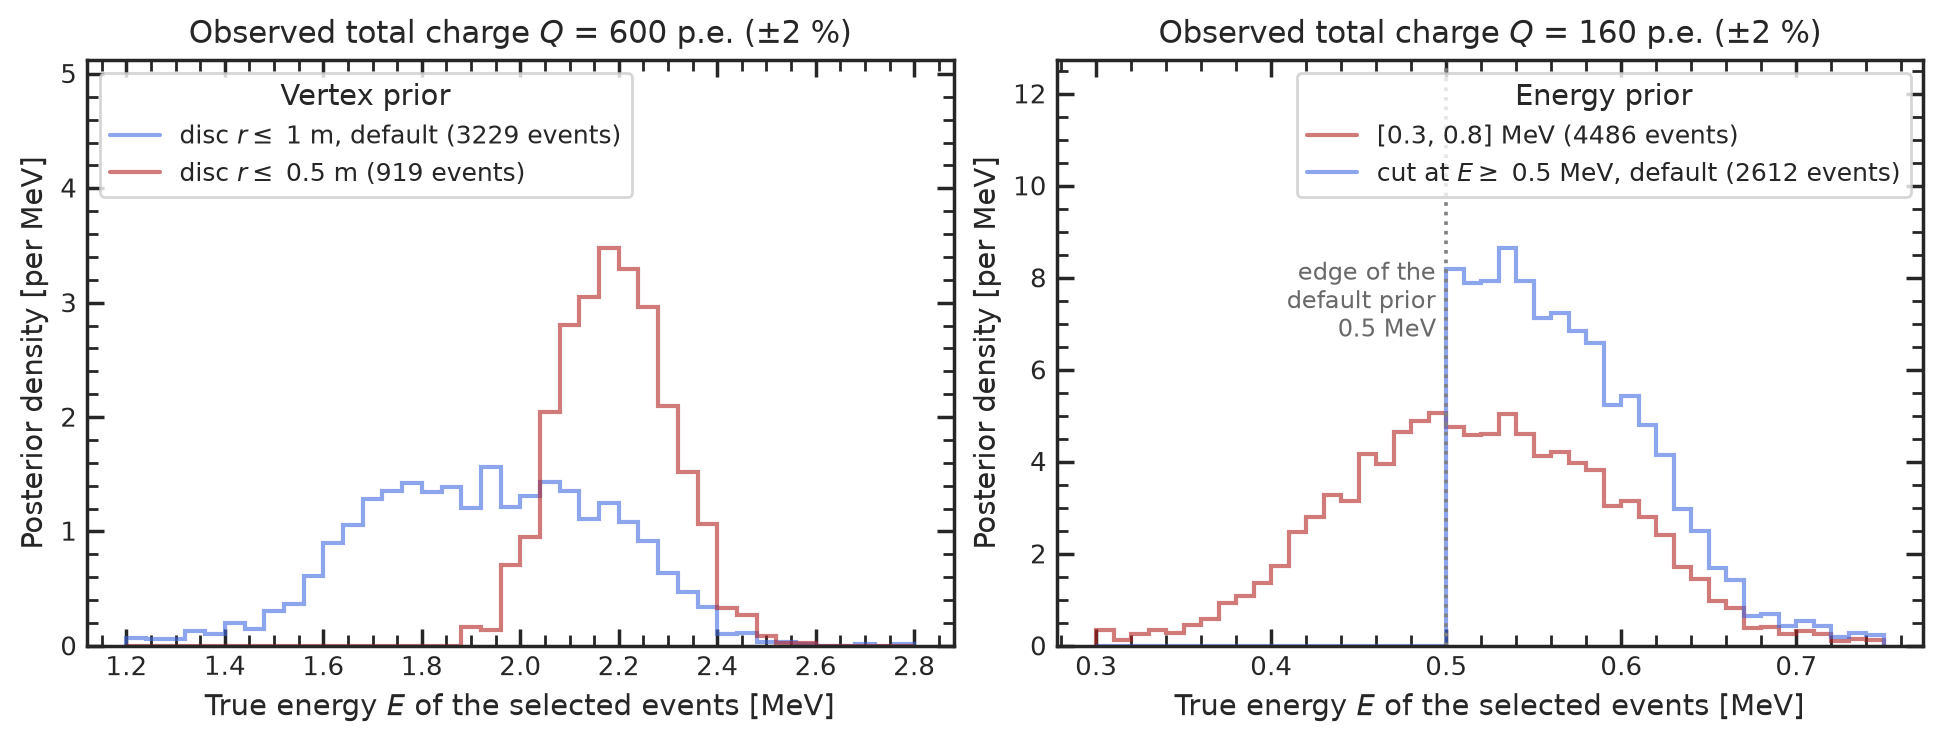

In [5]:
show("t1_2_prior_matters")

**Details** (the figure makes this concrete without any network: keeping the simulated events whose total charge Q
falls in a narrow window gives the posterior of E given Q alone, rejection ABC)

- *The prior shapes the answer:* for Q = 600 ± 2 % p.e. the energy is 1.93 MeV (16-84 %: 1.67-2.20) with the disc
  prior, but 2.19 MeV (2.08-2.31) if the vertex prior is restricted to r ≤ 0.5 m. The same observation gives a
  different answer, because central events collect less light and need more energy.
- *Edges:* for Q = 160 ± 2 % p.e. an energy prior extended to [0.3, 0.8] MeV puts (41.8 ± 0.7) % of the posterior
  below 0.5 MeV (4486 events in the window, binomial error); the default prior cuts that part away and the posterior
  piles up against the edge (median 0.563 ± 0.001 instead of 0.517 ± 0.002 MeV).
- Edge effects are not rare: 9.75 % of the prior lies within 5 cm of the wall and 4.4 % within 0.1 MeV of an energy
  limit.

*Figure:* `t1_2_prior_matters` (`task1_prior.py`). *Numbers:* `results/T1.json`.